<a href="https://colab.research.google.com/github/VTKhanhLinh/TH_MachineLearning/blob/main/Tuan_1/Bai_Tap_O_Lop/Bai_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Họ tên: Vũ Thị Khánh Linh

MSSV: 2045240158

BÀI 3. XÂY DỰNG MÔ HÌNH HỒI QUY TRÊN BỘ DỮ LIỆU TỰ CHỌN


In [ ]:
#Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

In [ ]:
#Tạo bộ dữ liệu sinh viên
# Số lượng sinh viên
n = 200

# Tạo số giờ học ngẫu nhiên từ 1 đến 10 giờ
gio_hoc = np.random.uniform(1, 10, n)

# Tạo điểm thi theo mối quan hệ tuyến tính
diem_thi = 2 + 0.8 * gio_hoc + np.random.normal(0, 1, n)

# Giới hạn điểm từ 0 đến 10
diem_thi = np.clip(diem_thi, 0, 10)

# Tạo bảng dữ liệu
df = pd.DataFrame({
    "Số giờ học": gio_hoc,
    "Điểm thi": diem_thi
})

# Làm tròn để hiển thị
print("10 sinh viên đầu tiên:")
display(df.head(10).round(2))

print("\nKích thước dữ liệu:", df.shape)
print("Số sinh viên:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

10 sinh viên đầu tiên:


,Số giờ học,Điểm thi
0,4.37,4.82
1,9.56,9.88
2,7.59,8.36
3,6.39,6.40
4,2.40,5.79
5,2.40,4.40
6,1.52,2.03
7,8.80,9.69
8,6.41,6.15
9,7.37,8.69



Kích thước dữ liệu: (200, 2)
Số sinh viên: 200
Số thuộc tính: 2


In [ ]:
#Khám phá và kiểm tra dữ liệu
# Kiểm tra thông tin dữ liệu
print("Thông tin bộ dữ liệu:")
df.info()

# Thống kê mô tả
print("\nThống kê mô tả:")
display(df.describe().round(2))

# Kiểm tra dữ liệu thiếu
print("\nSố giá trị thiếu:")
print(df.isnull().sum())

# Kiểm tra dữ liệu trùng lặp
print("\nSố dòng trùng lặp:", df.duplicated().sum())

Thông tin bộ dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Số giờ học  200 non-null    float64
 1   Điểm thi    200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB

Thống kê mô tả:


,Số giờ học,Điểm thi
count,200.00,200.00
mean,5.36,6.33
std,2.65,2.27
min,1.05,1.64
25%,3.06,4.27
50%,5.45,6.25
75%,7.81,8.37
max,9.88,10.00



Số giá trị thiếu:
Số giờ học    0
Điểm thi      0
dtype: int64

Số dòng trùng lặp: 0


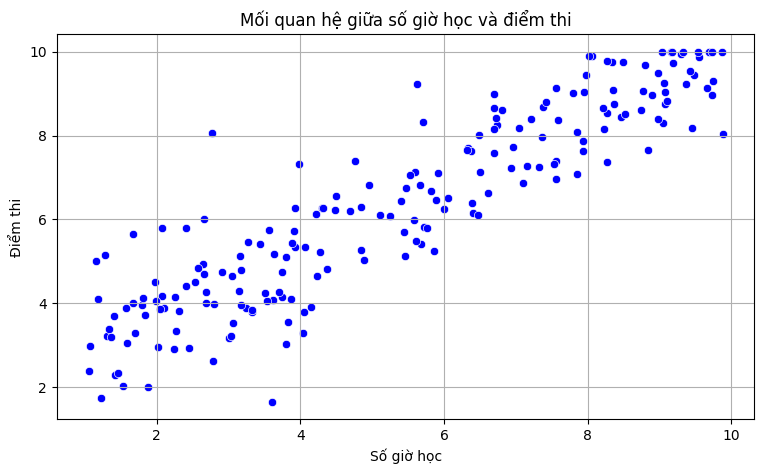

In [ ]:
#Trực quan hóa dữ liệu
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Số giờ học",
    y="Điểm thi",
    color="blue"
)

plt.title("Mối quan hệ giữa số giờ học và điểm thi")
plt.xlabel("Số giờ học")
plt.ylabel("Điểm thi")
plt.grid(True)
plt.show()

Ma trận tương quan:


,Số giờ học,Điểm thi
Số giờ học,1.00,0.91
Điểm thi,0.91,1.00


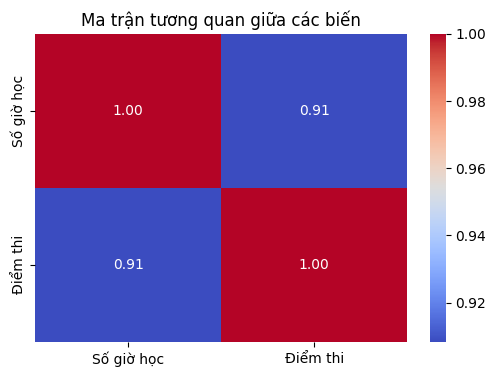

In [ ]:
#Phân tích tương quan
# Tính ma trận tương quan
tuong_quan = df.corr()

print("Ma trận tương quan:")
display(tuong_quan.round(2))

# Vẽ biểu đồ
plt.figure(figsize=(6, 4))

sns.heatmap(
    tuong_quan,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Ma trận tương quan giữa các biến")
plt.show()

In [ ]:
#Chia dữ liệu huấn luyện và kiểm tra
# Biến đầu vào
X = df[["Số giờ học"]]

# Biến mục tiêu
y = df["Điểm thi"]

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))

Số mẫu huấn luyện: 160
Số mẫu kiểm tra: 40


In [ ]:
#Xây dựng và huấn luyện mô hình
# Khởi tạo mô hình
model = LinearRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

# Hiển thị các hệ số
print("Hệ số góc:", round(model.coef_[0], 4))
print("Hệ số chặn:", round(model.intercept_, 4))

print(
    f"Phương trình hồi quy: "
    f"Điểm thi = {model.coef_[0]:.4f} × Số giờ học "
    f"+ ({model.intercept_:.4f})"
)

Hệ số góc: 0.7991
Hệ số chặn: 2.0492
Phương trình hồi quy: Điểm thi = 0.7991 × Số giờ học + (2.0492)


In [ ]:
#Dự đoán điểm thi trên tập kiểm tra
# Dự đoán điểm thi
y_pred = model.predict(X_test)

# Tạo bảng so sánh
ket_qua = pd.DataFrame({
    "Số giờ học": X_test["Số giờ học"].values,
    "Điểm thực tế": y_test.values,
    "Điểm dự đoán": y_pred,
    "Sai số": y_test.values - y_pred
})

print("Kết quả dự đoán:")
display(ket_qua.head(15).round(2))

Kết quả dự đoán:


,Số giờ học,Điểm thực tế,Điểm dự đoán,Sai số
0,5.44,5.70,6.40,-0.70
1,2.65,6.02,4.17,1.85
2,6.47,6.10,7.22,-1.11
3,3.14,4.29,4.56,-0.26
4,1.06,2.96,2.90,0.07
5,8.84,7.64,9.12,-1.47
6,9.88,8.04,9.95,-1.91
7,7.10,6.86,7.72,-0.86
8,6.81,8.60,7.49,1.11
9,6.96,7.72,7.61,0.11


In [ ]:
#Đánh giá mô hình
# Tính các chỉ số đánh giá
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Hiển thị kết quả bằng tiếng Việt
print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH")
print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")
print(f"Sai số bình phương trung bình (MSE): {mse:.4f}")
print(f"Căn bậc hai sai số bình phương (RMSE): {rmse:.4f}")
print(f"Hệ số xác định (R²): {r2:.4f}")

KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH
Sai số tuyệt đối trung bình (MAE): 0.8080
Sai số bình phương trung bình (MSE): 1.0226
Căn bậc hai sai số bình phương (RMSE): 1.0112
Hệ số xác định (R²): 0.7644


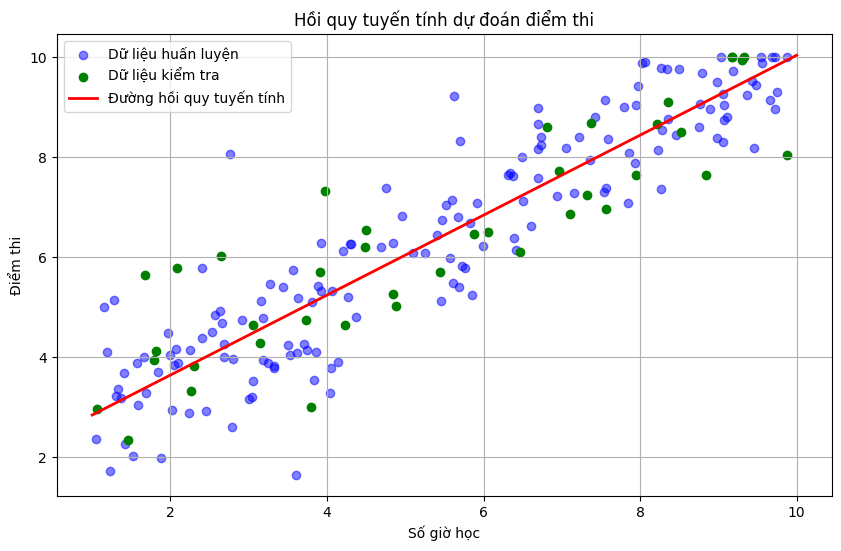

In [ ]:
#Vẽ đường hồi quy tuyến tính
# Tạo dãy số giờ học để vẽ đường hồi quy
gio_hoc_line = np.linspace(1, 10, 100)

X_line = pd.DataFrame({
    "Số giờ học": gio_hoc_line
})

diem_line = model.predict(X_line)

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))

plt.scatter(
    X_train["Số giờ học"],
    y_train,
    color="blue",
    alpha=0.5,
    label="Dữ liệu huấn luyện"
)

plt.scatter(
    X_test["Số giờ học"],
    y_test,
    color="green",
    label="Dữ liệu kiểm tra"
)

plt.plot(
    gio_hoc_line,
    diem_line,
    color="red",
    linewidth=2,
    label="Đường hồi quy tuyến tính"
)

plt.xlabel("Số giờ học")
plt.ylabel("Điểm thi")
plt.title("Hồi quy tuyến tính dự đoán điểm thi")
plt.legend()
plt.grid(True)
plt.show()

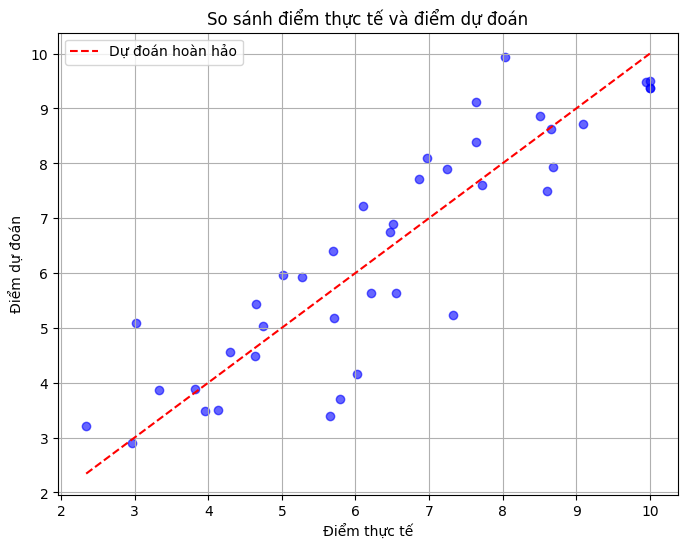

In [ ]:
#So sánh điểm thực tế và điểm dự đoán
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    color="blue",
    alpha=0.6
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Dự đoán hoàn hảo"
)

plt.xlabel("Điểm thực tế")
plt.ylabel("Điểm dự đoán")
plt.title("So sánh điểm thực tế và điểm dự đoán")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Dự đoán điểm thi của sinh viên mới
# Tạo dữ liệu sinh viên mới
sinh_vien_moi = pd.DataFrame({
    "Số giờ học": [2, 4, 6, 8, 10]
})

# Dự đoán điểm
diem_du_doan = model.predict(sinh_vien_moi)

# Giới hạn điểm từ 0 đến 10
diem_du_doan = np.clip(diem_du_doan, 0, 10)

# Hiển thị kết quả
bang_du_doan = pd.DataFrame({
    "Số giờ học": sinh_vien_moi["Số giờ học"],
    "Điểm thi dự đoán": diem_du_doan
})

print("DỰ ĐOÁN ĐIỂM THI SINH VIÊN MỚI")
display(bang_du_doan.round(2))

DỰ ĐOÁN ĐIỂM THI SINH VIÊN MỚI


,Số giờ học,Điểm thi dự đoán
0,2,3.65
1,4,5.25
2,6,6.84
3,8,8.44
4,10,10.00
